In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

np.random.seed(42)  # i chose 42 randomally i just needed a fixed starting point


In [2]:
# Image Generation:
height = 512
width = 640

#opencv uses bgr not rgb
BACKGROUND = (228, 222, 238)   # plasma
RBC_EDGE   = (120, 105, 200)   # red cell rim (thicker, more hemoglobin)
RBC_BODY   = (145, 130, 215)
RBC_MID    = (170, 158, 225)   # transition towards the centre
RBC_PALLOR = (200, 190, 232)   # pale centre of the biconcave disc
CYTOPLASM  = (215, 190, 205)   # pale lilac neutrophil cytoplasm
LYMPH_CYTO = (220, 185, 170)   # light-blue lymphocyte cytoplasm
NUCLEUS    = (140, 50, 95)     # dark purple nucleus
PLATELET   = (150, 80, 130)


medical_img = np.zeros((height, width, 3), dtype=np.uint8)
medical_img[:] = BACKGROUND #sets all pixels to background color


placed = [] #any object we'll draw stored as x,y,radius

def free_spot(x, y, r, overlap=0.9):
    # True if a cell of radius r at (x, y) would not overlap too much with any placed object
    for px, py, pr in placed:
        if np.hypot(x - px, y - py) < overlap * (r + pr): #euclidean distance between the 2 centers
            return False
    return True

In [3]:
#White blood cells

# Neutrophil: large cell, nucleus made of 4 lobes joined by thin bridges
nx, ny, nr = 200, 180, 34
cv2.circle(medical_img, (nx, ny), nr, CYTOPLASM, -1)
lobes = [(-14, -8), (-2, -16), (12, -6), (6, 12)]
for dx, dy in lobes:
    cv2.ellipse(medical_img, (nx + dx, ny + dy), (11, 9), np.random.uniform(0, 180), 0, 360, NUCLEUS, -1)
for (x1, y1), (x2, y2) in zip(lobes[:-1], lobes[1:]):
    cv2.line(medical_img, (nx + x1, ny + y1), (nx + x2, ny + y2), NUCLEUS, 4)
placed.append((nx, ny, nr))

# Lymphocyte: smaller cell, big round nucleus, thin blue rim of cytoplasm
lx, ly, lr = 470, 340, 24
cv2.circle(medical_img, (lx, ly), lr, LYMPH_CYTO, -1)
cv2.circle(medical_img, (lx - 3, ly + 1), 19, NUCLEUS, -1)
placed.append((lx, ly, lr))

# ---- Abnormal finding: two sickle cells (crescent-shaped red cells) ----
for sx, sy, angle in [(380, 110, 30), (130, 400, -50)]:
    cv2.ellipse(medical_img, (sx, sy), (32, 12), angle, 0, 360, RBC_EDGE, -1)
    cv2.ellipse(medical_img, (sx, sy), (29, 9), angle, 0, 360, RBC_BODY, -1)
    # cut out one side with background colour -> crescent shape
    t = np.deg2rad(angle + 90)
    cut_center = (int(sx + 10 * np.cos(t)), int(sy + 10 * np.sin(t)))
    cv2.ellipse(medical_img, cut_center, (26, 9), angle, 0, 360, BACKGROUND, -1)
    placed.append((sx, sy, 30))

# ---- Normal red blood cells: try many random positions, keep the free ones ----
for attempt in range(4000):
    r = np.random.randint(17, 22)
    x = np.random.randint(-10, width + 10)      # cells may be cut by the image border
    y = np.random.randint(-10, height + 10)
    if not free_spot(x, y, r):
        continue
    axes = (r, int(r * np.random.uniform(0.85, 1.0)))   # slightly oval
    angle = np.random.uniform(0, 180)
    # rim -> body -> lighter ring -> pale centre (biconcave disc)
    cv2.ellipse(medical_img, (x, y), axes, angle, 0, 360, RBC_EDGE, -1)
    cv2.ellipse(medical_img, (x, y), (axes[0] - 3, axes[1] - 3), angle, 0, 360, RBC_BODY, -1)
    cv2.ellipse(medical_img, (x, y), (int(axes[0] * 0.55), int(axes[1] * 0.55)), angle, 0, 360, RBC_MID, -1)
    cv2.ellipse(medical_img, (x, y), (int(axes[0] * 0.35), int(axes[1] * 0.35)), angle, 0, 360, RBC_PALLOR, -1)
    placed.append((x, y, r))

# ---- Platelets: 12 small purple fragments in the gaps ----
count = 0
for attempt in range(2000):
    x = np.random.randint(0, width)
    y = np.random.randint(0, height)
    if count < 12 and free_spot(x, y, 4, overlap=1.0):
        size = (np.random.randint(2, 5), np.random.randint(2, 4))
        cv2.ellipse(medical_img, (x, y), size, np.random.uniform(0, 180), 0, 360, PLATELET, -1)
        placed.append((x, y, 4))
        count += 1

print("Red blood cells drawn:", len(placed) - 2 - 2 - count)

# Keep a copy of the clean image (before any acquisition problems)
clean_img = medical_img.copy()

Red blood cells drawn: 191


In [4]:
# Adding Some Noise

# Convert to grayscale
gray_img = cv2.cvtColor(medical_img, cv2.COLOR_BGR2GRAY)

# bad contrast: intensities more bright -> to test histogram
gray_img = 0.5 * gray_img + 110
gray_img = np.clip(gray_img, 0, 255).astype(np.uint8)

# gaussian noise -> gaussian filter
noise = np.random.normal(0, 6, gray_img.shape)
gray_img = np.clip(
    gray_img.astype(np.float32) + noise,
    0,
    255
).astype(np.uint8)

# salt and pepper noise -> median filter later
r = np.random.rand(height, width)
gray_img[r < 0.005] = 0
gray_img[r > 0.995] = 255

Original shape: (512, 640, 3)
Grayscale shape: (512, 640)
Data type: uint8


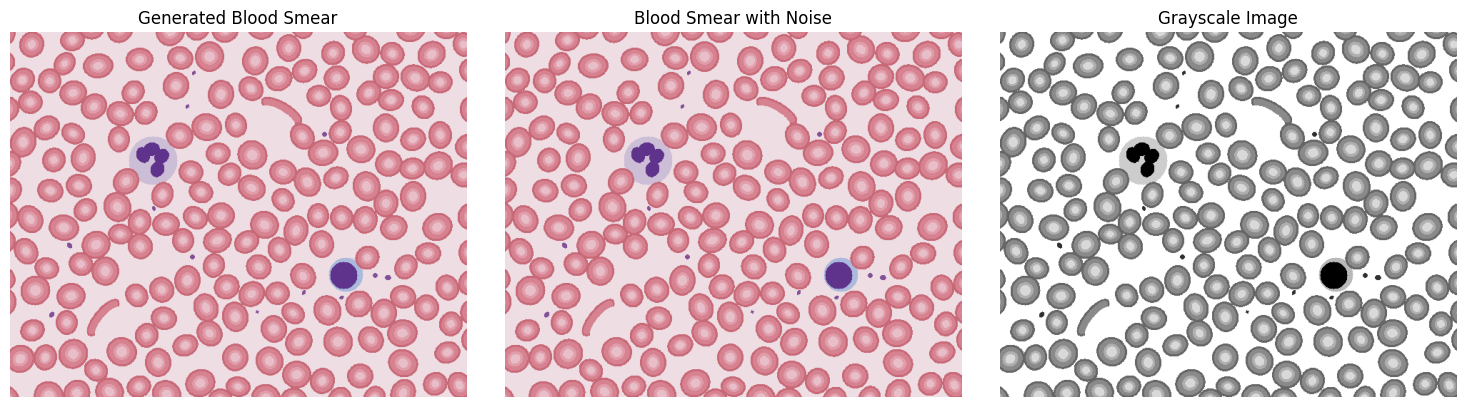

In [5]:
gray_img = cv2.cvtColor(medical_img, cv2.COLOR_BGR2GRAY)

print("Original shape:", medical_img.shape)
print("Grayscale shape:", gray_img.shape)
print("Data type:", gray_img.dtype)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(clean_img, cv2.COLOR_BGR2RGB))
plt.title("Generated Blood Smear")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(medical_img, cv2.COLOR_BGR2RGB))
plt.title("Blood Smear with Noise")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gray_img, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()


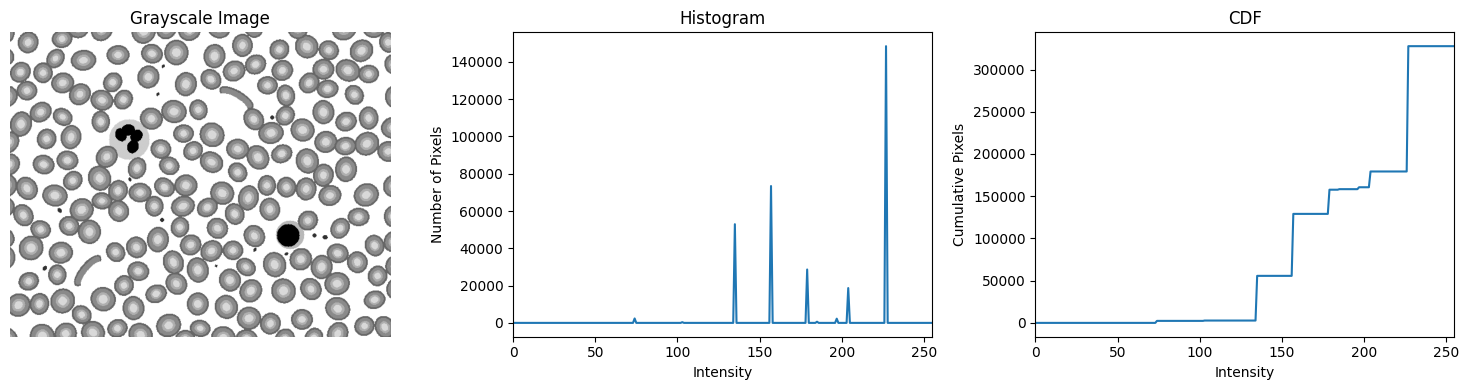

In [6]:
#Histogram and CDF:
hist, bins = np.histogram(gray_img.flatten(), 256, [0, 256])
cdf = hist.cumsum()

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(gray_img, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.plot(hist)
plt.title("Histogram")
plt.xlabel("Intensity")
plt.ylabel("Number of Pixels")
plt.xlim([0, 255])

plt.subplot(1, 3, 3)
plt.plot(cdf)
plt.title("CDF")
plt.xlabel("Intensity")
plt.ylabel("Cumulative Pixels")
plt.xlim([0, 255])

plt.tight_layout()
plt.show()


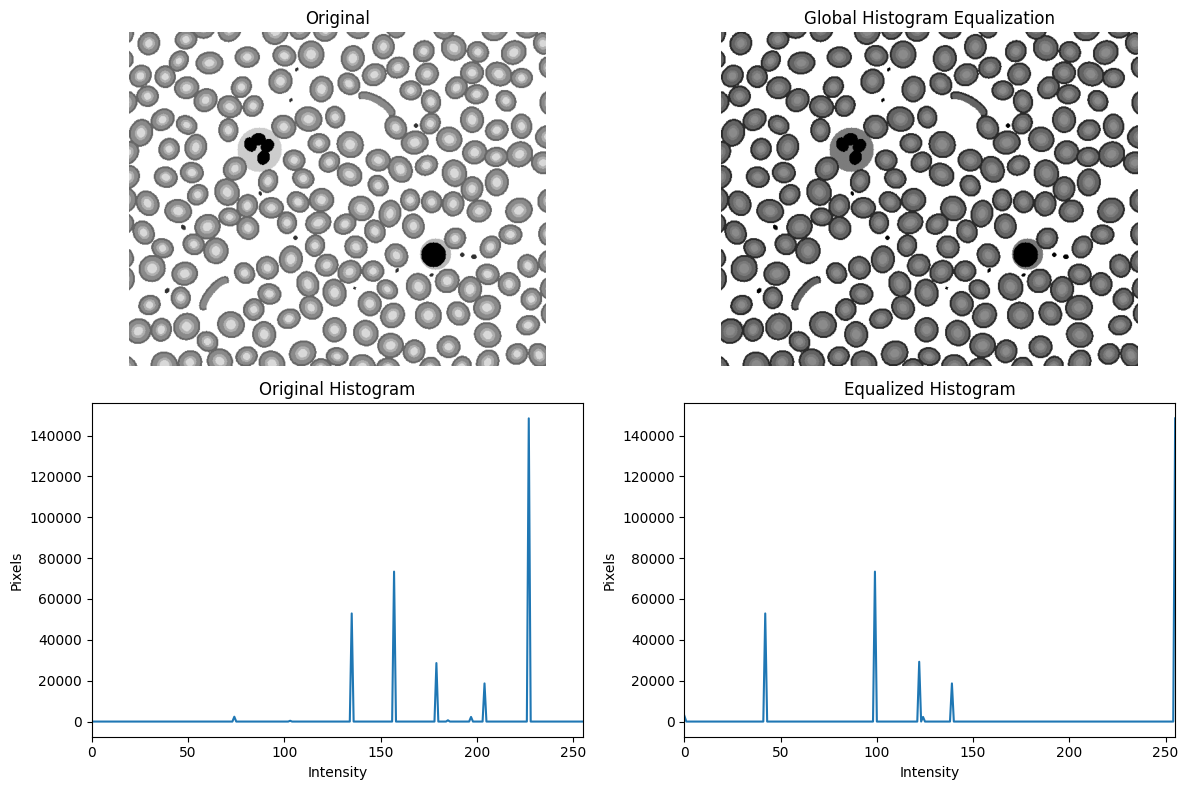

In [7]:
#Global Histogram cv2.equalizeHist()

equalized_cv2 = cv2.equalizeHist(gray_img)

hist_equalized, _ = np.histogram(equalized_cv2.flatten(), 256, [0, 256])

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(gray_img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(equalized_cv2, cmap="gray")
plt.title("Global Histogram Equalization")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.plot(hist)
plt.title("Original Histogram")
plt.xlabel("Intensity")
plt.ylabel("Pixels")
plt.xlim([0, 255])

plt.subplot(2, 2, 4)
plt.plot(hist_equalized)
plt.title("Equalized Histogram")
plt.xlabel("Intensity")
plt.ylabel("Pixels")
plt.xlim([0, 255])

plt.tight_layout()
plt.show()


Maximum absolute difference: 0


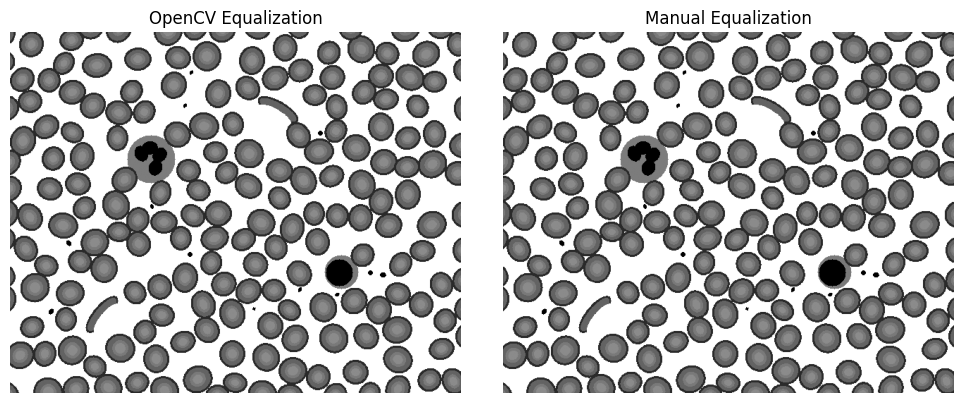

In [8]:
#Reproduce equalization manually:

cdf_min = cdf[cdf > 0][0]
total_pixels = gray_img.shape[0] * gray_img.shape[1]
L = 256

lut = np.round(
    (cdf - cdf_min) /
    (total_pixels - cdf_min) *
    (L - 1)
)

lut = np.clip(lut, 0, 255).astype(np.uint8)
equalized_manual = lut[gray_img]

difference = np.abs(
    equalized_cv2.astype(np.int16) - equalized_manual.astype(np.int16)
)

print("Maximum absolute difference:", np.max(difference))

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(equalized_cv2, cmap="gray")
plt.title("OpenCV Equalization")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized_manual, cmap="gray")
plt.title("Manual Equalization")
plt.axis("off")

plt.tight_layout()
plt.show()


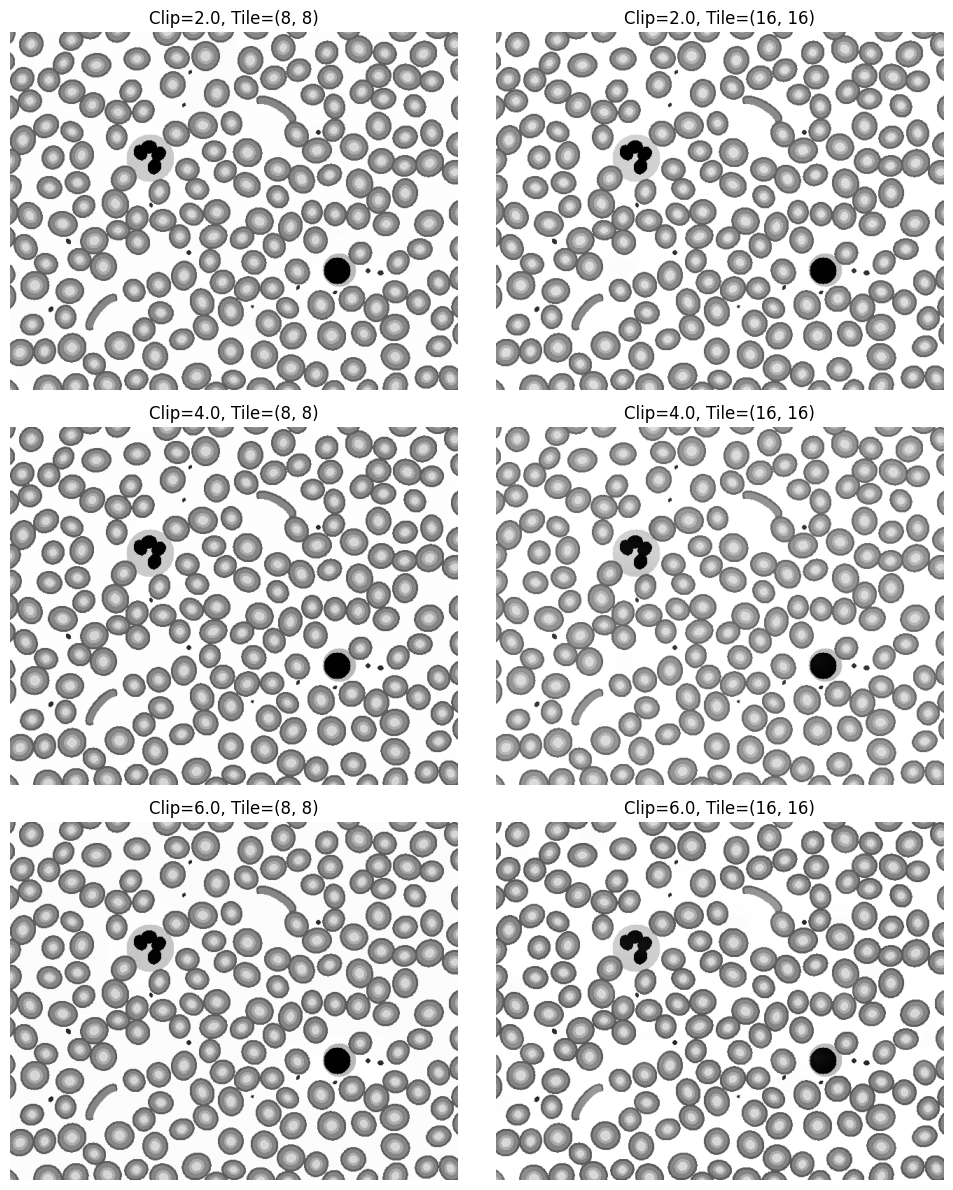

In [9]:
#CLAHE
clip_limits = [2.0, 4.0, 6.0]
tile_sizes = [(8, 8), (16, 16)]

clahe_results = {}

for clip in clip_limits:
    for tile in tile_sizes:
        clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=tile)
        clahe_results[(clip, tile)] = clahe.apply(gray_img)

plt.figure(figsize=(10, 12))

position = 1
for clip in clip_limits:
    for tile in tile_sizes:
        plt.subplot(3, 2, position)
        plt.imshow(clahe_results[(clip, tile)], cmap="gray")
        plt.title(f"Clip={clip}, Tile={tile}")
        plt.axis("off")
        position += 1

plt.tight_layout()
plt.show()


In [10]:
clahe_selected = clahe_results[(2.0, (8, 8))]


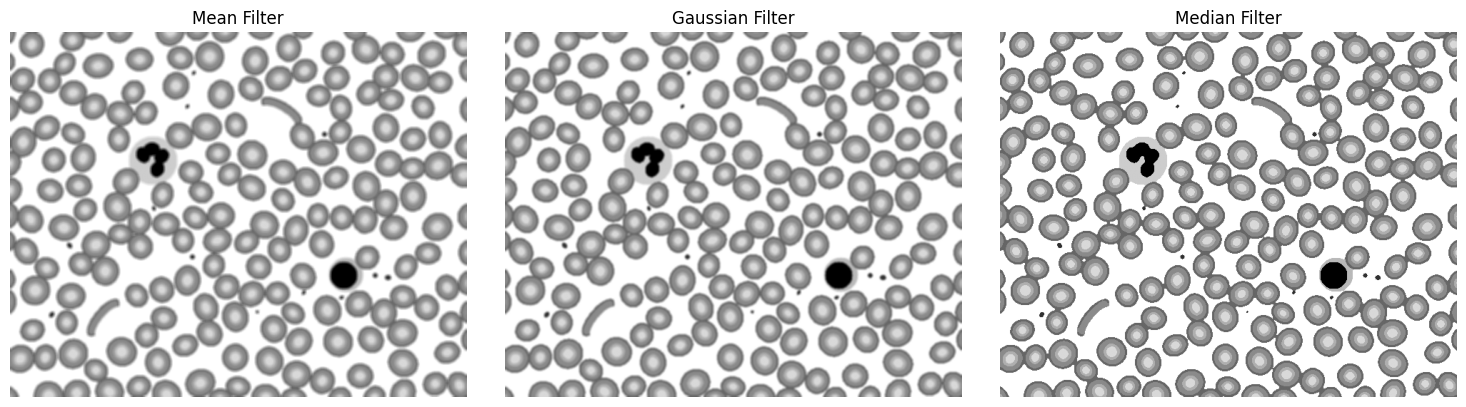

In [11]:
#Spatial Filters:

mean_filtered = cv2.blur(gray_img, (5, 5))
gaussian_filtered = cv2.GaussianBlur(gray_img, (5, 5), sigmaX=1.5)
median_filtered = cv2.medianBlur(gray_img, ksize=5)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(mean_filtered, cmap="gray")
plt.title("Mean Filter")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gaussian_filtered, cmap="gray")
plt.title("Gaussian Filter")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(median_filtered, cmap="gray")
plt.title("Median Filter")
plt.axis("off")

plt.tight_layout()
plt.show()


In [12]:
#Outputs Comparisons:

outputs = {
    "Global Equalization": equalized_cv2,
    "Manual Equalization": equalized_manual,
    "CLAHE": clahe_selected,
    "Mean Filter": mean_filtered,
    "Gaussian Filter": gaussian_filtered,
    "Median Filter": median_filtered
}

print(f"{'Output':<22}{'Min':<8}{'Max':<8}{'Mean':<12}{'Std Dev':<12}")
print("-" * 62)

for name, img in outputs.items():
    print(
        f"{name:<22}"
        f"{np.min(img):<8}"
        f"{np.max(img):<8}"
        f"{np.mean(img):<12.2f}"
        f"{np.std(img):<12.2f}"
    )


Output                Min     Max     Mean        Std Dev     
--------------------------------------------------------------
Global Equalization   0       255     164.11      86.79       
Manual Equalization   0       255     164.11      86.79       
CLAHE                 72      230     189.48      40.39       
Mean Filter           74      227     189.41      32.65       
Gaussian Filter       74      227     189.41      33.55       
Median Filter         74      227     189.19      38.53       


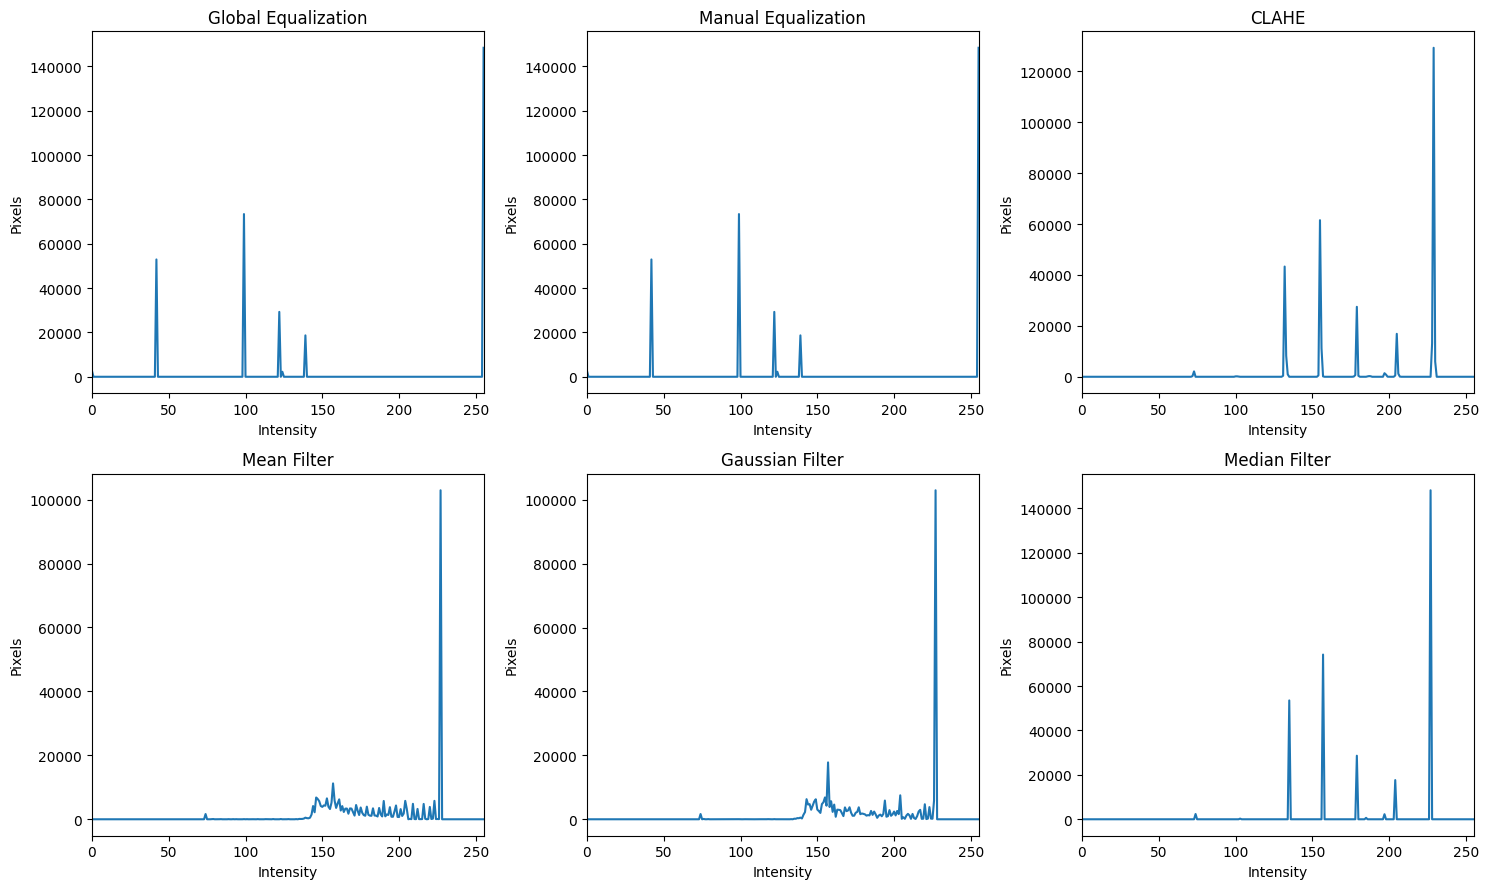

In [13]:
plt.figure(figsize=(15, 9))

position = 1
for name, img in outputs.items():
    hist_out, _ = np.histogram(img.flatten(), 256, [0, 256])

    plt.subplot(2, 3, position)
    plt.plot(hist_out)
    plt.title(name)
    plt.xlabel("Intensity")
    plt.ylabel("Pixels")
    plt.xlim([0, 255])
    position += 1

plt.tight_layout()
plt.show()


# Conclusion:

Global histogram equalization improved the whole contrast of the image and CLAHE was better at enhancing contrast in locally. The mean and gaussian filters smoothed the image, but the median filter worked better for removing salt and pepper noise.

# Data Leakage:

Preprocessing settings should be chosen using the training data only. the same settings should be applied to the test data without changing them. If the test data is used while deciding the preprocessing settings, this can cause data leakage and make the final results look better than they really are.


## Challenge Task

**Pipeline A:** median filter → global histogram equalization  
**Pipeline B:** CLAHE → median filter


Mean Absolute Difference (MAD): 48.68447


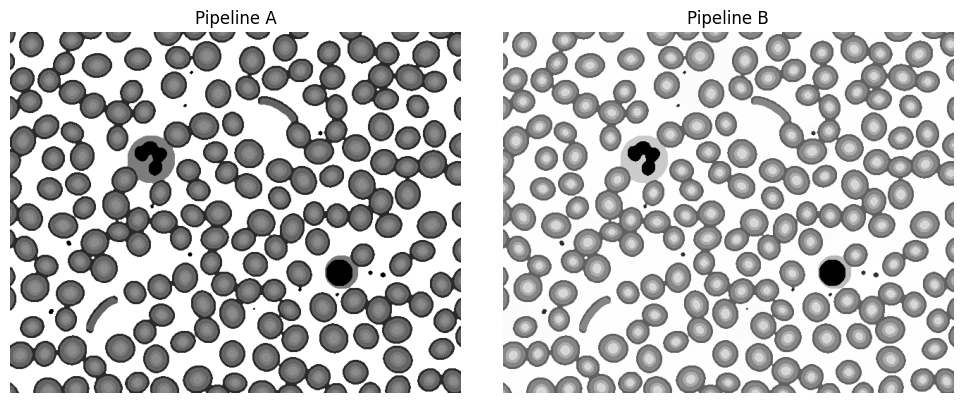

In [14]:
# Pipeline A
pipeline_A_median = cv2.medianBlur(gray_img, 5)
pipeline_A = cv2.equalizeHist(pipeline_A_median)

# Pipeline B
challenge_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
pipeline_B_clahe = challenge_clahe.apply(gray_img)
pipeline_B = cv2.medianBlur(pipeline_B_clahe, 5)

mad = np.mean(
    np.abs(
        pipeline_A.astype(np.float32) - pipeline_B.astype(np.float32)
    )
)

print("Mean Absolute Difference (MAD):", mad)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(pipeline_A, cmap="gray")
plt.title("Pipeline A")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(pipeline_B, cmap="gray")
plt.title("Pipeline B")
plt.axis("off")

plt.tight_layout()
plt.show()


The two pipelines give different results because the order of preprocessing changes the image before the next operation is applied. The non-zero MAD shows that the two final images are not identical.
